# ROC/PR曲线手推可视化Demo
完全对应之前5样本手推的计算过程，跑一遍代码就能直观看到曲线是怎么随着阈值滑动生成的。

样本设定：预测概率从高到低为 `[0.9, 0.8, 0.7, 0.6, 0.5]`，对应真实标签为 `[P, N, P, N, P]`（共3个正样本，2个负样本）。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 配置中文显示
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

## 1. 逐阈值滑动计算指标
从高到低滑动阈值，每纳入一个新样本，就记录一次当前的TP、FP、TPR、FPR、Precision、Recall，和之前手推的计算步骤完全一致。

In [3]:
# 样本数据：概率从高到低排序
predictions = np.array([0.9, 0.8, 0.7, 0.6, 0.5])
labels = np.array([1, 0, 1, 0, 1])  # 1=正样本P, 0=负样本N

total_pos = np.sum(labels == 1)  # 总正样本数=3
total_neg = np.sum(labels == 0)  # 总负样本数=2

# 逐点计算
fpr_list = [0.0]
tpr_list = [0.0]
precision_list = [1.0]  # 行业惯例起点：无预测正例时Precision=1
recall_list = [0.0]

tp = 0
fp = 0

for prob, label in zip(predictions, labels):
    if label == 1:
        tp += 1
    else:
        fp += 1
    tpr = tp / total_pos
    fpr = fp / total_neg
    precision = tp / (tp + fp)
    recall = tpr
    fpr_list.append(fpr)
    tpr_list.append(tpr)
    precision_list.append(precision)
    recall_list.append(recall)

print("计算得到的ROC点(FPR, TPR):")
for fpr, tpr in zip(fpr_list, tpr_list):
    print(f"  ({fpr:.2f}, {tpr:.2f})")

print("\n计算得到的PR点(Recall, Precision):")
for r, p in zip(recall_list, precision_list):
    print(f"  ({r:.2f}, {p:.2f})")

计算得到的ROC点(FPR, TPR):
  (0.00, 0.00)
  (0.00, 0.33)
  (0.50, 0.33)
  (0.50, 0.67)
  (1.00, 0.67)
  (1.00, 1.00)

计算得到的PR点(Recall, Precision):
  (0.00, 1.00)
  (0.33, 1.00)
  (0.33, 0.50)
  (0.67, 0.67)
  (0.67, 0.50)
  (1.00, 0.60)


## 2. 绘制ROC曲线
阶梯线就是阈值滑动过程中，每纳入一个样本对应的位置；对角线代表随机猜的水平(AUC=0.5)。

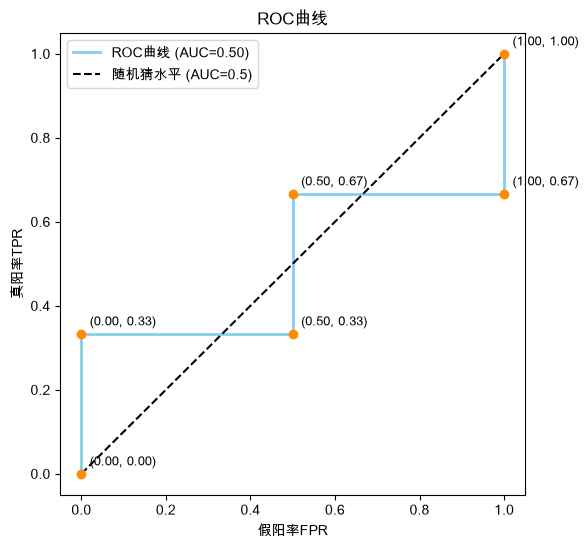

In [15]:
from sklearn.metrics import auc

# 假设 fpr_list 和 tpr_list 是假阳率和真阳率的列表
# 计算 ROC 曲线下的面积 (AUC)
roc_auc = auc(fpr_list, tpr_list)

plt.figure(figsize=(6,6))
# 画阶梯ROC曲线
plt.step(fpr_list, tpr_list, where='post', linewidth=2, label=f'ROC曲线 (AUC={roc_auc:.2f})',color='skyblue')
# 标注每个计算点
for fpr, tpr in zip(fpr_list, tpr_list):
    plt.scatter(fpr, tpr, c='darkorange', zorder=5)
    plt.text(fpr+0.02, tpr+0.02, f'({fpr:.2f}, {tpr:.2f})', fontsize=9)
# 对角线参考线
plt.plot([0,1], [0,1], 'k--', label='随机猜水平 (AUC=0.5)')

plt.xlabel('假阳率FPR')
plt.ylabel('真阳率TPR')
plt.title('ROC曲线')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.legend()

# 保存图片到文件
plt.savefig('roc_curve.png', dpi=600)

# 显示图像
plt.show()
plt.close()

## 3. 绘制PR曲线
锯齿形状对应之前手推的观察：纳入负样本时精确率往下掉，纳入正样本时召回率往右走。

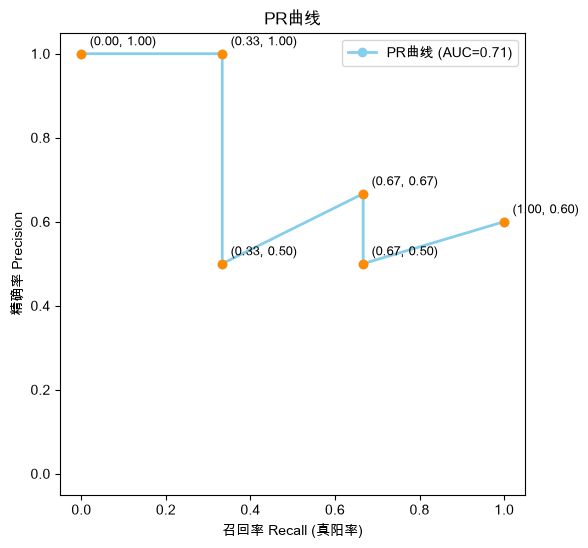

In [14]:
from sklearn.metrics import auc
import matplotlib.pyplot as plt

# 假设 recall_list 和 precision_list 是召回率和精确率的列表
# 计算 PR 曲线下的面积 (AUC)
pr_auc = auc(recall_list, precision_list)

plt.figure(figsize=(6,6))
# 画 PR 曲线
plt.plot(recall_list, precision_list, linewidth=2, marker='o', label=f'PR曲线 (AUC={pr_auc:.2f})',color='skyblue')
# 标注每个计算点
for r, p in zip(recall_list, precision_list):
    plt.scatter(r, p, c='darkorange', zorder=5)
    plt.text(r+0.02, p+0.02, f'({r:.2f}, {p:.2f})', fontsize=9)

plt.xlabel('召回率 Recall (真阳率)')
plt.ylabel('精确率 Precision')
plt.title('PR曲线')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.legend()

# 保存图片到文件
plt.savefig('pr_curve.png', dpi=600)

# 显示图像
plt.show()
plt.close()